# 03 Analisis

Data dibaca dari database `kinerja_cabang.db` hasil `src/load.py`, terutama dari
view `v_kinerja_cabang` dan `v_kinerja_wilayah`. Query di notebook ini sama dengan
yang ada di `sql/03_analisis.sql`.

Posisi akhir yang dipakai adalah Desember 2025. Capaian laba memakai laba YTD
(dijumlahkan sejak Januari), karena laba satu bulan bisa naik turun.

Batas yang dipakai untuk menandai cabang:
- NPL di atas 5%
- capaian kredit di bawah 95%
- capaian laba YTD di bawah 90%

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("../database/kinerja_cabang.db")

def query(sql):
    return pd.read_sql(sql, conn)

pd.set_option("display.max_columns", None)

# Pengaturan grafik
BIRU, ORANYE, MERAH, ABU = "#2a78d6", "#eb6834", "#d03b3b", "#b5b4ae"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9})
GAMBAR = "../docs/images/"

In [2]:
import os
os.makedirs(GAMBAR, exist_ok=True)

## 1. Gambaran Umum Seluruh Cabang

In [3]:
total = query('''
    SELECT
        periode,
        SUM(kredit_outstanding) / 1e6 AS kredit_triliun,
        SUM(total_dpk) / 1e6          AS dpk_triliun,
        SUM(laba_sebelum_pajak)       AS laba,
        ROUND(100.0 * SUM(kredit_bermasalah) / SUM(kredit_outstanding), 2) AS npl
    FROM v_kinerja_cabang
    GROUP BY periode
    ORDER BY periode
''')
total.iloc[[0, 11, 12, 23]].round(2)

,periode,kredit_triliun,dpk_triliun,laba,npl
0,2024-01,30.06,36.07,93718.87,2.48
11,2024-12,33.44,36.32,106121.68,2.58
12,2025-01,33.03,38.93,101414.59,2.57
23,2025-12,36.84,39.32,116645.49,2.54


In [4]:
des24 = total[total["periode"] == "2024-12"].iloc[0]
des25 = total[total["periode"] == "2025-12"].iloc[0]

print("Pertumbuhan kredit  :", round(100 * (des25["kredit_triliun"] / des24["kredit_triliun"] - 1), 2), "%")
print("Pertumbuhan DPK     :", round(100 * (des25["dpk_triliun"] / des24["dpk_triliun"] - 1), 2), "%")

capaian_tahunan = query('''
    SELECT tahun, ROUND(100.0 * SUM(laba_sebelum_pajak) / SUM(target_laba), 2) AS capaian_laba
    FROM v_kinerja_cabang
    GROUP BY tahun
''')
capaian_tahunan

Pertumbuhan kredit  : 10.17 %
Pertumbuhan DPK     : 8.24 %


,tahun,capaian_laba
0,2024,100.12
1,2025,97.10


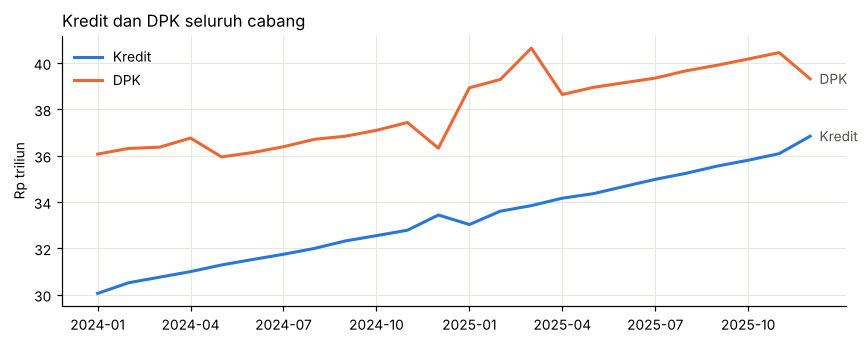

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(total["periode"], total["kredit_triliun"], color=BIRU, lw=2, label="Kredit")
ax.plot(total["periode"], total["dpk_triliun"], color=ORANYE, lw=2, label="DPK")

ax.text(23.3, total["kredit_triliun"].iloc[-1], "Kredit", color="#52514e", va="center")
ax.text(23.3, total["dpk_triliun"].iloc[-1], "DPK", color="#52514e", va="center")

ax.set_xticks(range(0, 24, 3))
ax.set_ylabel("Rp triliun")
ax.set_title("Kredit dan DPK seluruh cabang", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(GAMBAR + "tren_kredit_dpk.png")
plt.show()

Kredit naik cukup stabil sepanjang dua tahun, sedangkan DPK lebih naik turun.
Ada beberapa pola yang berulang:
- DPK turun di Desember. Penurunannya berasal dari giro, kemungkinan karena dana
  pemerintah daerah dipakai untuk belanja akhir tahun.
- DPK naik di bulan Lebaran (April 2024 dan Maret 2025), terutama dari tabungan.
- Kredit sedikit turun di Januari setelah naik di Desember.

Secara keseluruhan target laba 2024 tercapai, tapi capaian 2025 turun di bawah 100%.
Bagian berikutnya melihat cabang mana yang menyebabkan hal ini.

## 2. Capaian per Wilayah

In [6]:
query('''
    SELECT wilayah, jumlah_cabang, capaian_kredit, capaian_dpk, capaian_laba_ytd, npl
    FROM v_kinerja_wilayah
    WHERE periode = '2025-12'
    ORDER BY capaian_laba_ytd DESC
''')

,wilayah,jumlah_cabang,capaian_kredit,capaian_dpk,capaian_laba_ytd,npl
0,Mataraman,8,101.82,99.49,100.46,2.46
1,Surabaya Raya,6,100.53,97.09,98.29,2.18
2,Madura & Pantura,6,98.96,98.76,95.89,3.17
3,Malang Raya,6,97.84,100.53,94.56,2.41
4,Tapal Kuda,4,100.66,103.15,92.31,3.09


Tapal Kuda punya capaian kredit dan DPK di atas 100%, tapi capaian labanya paling rendah.
Ini tanda ada masalah di satu atau dua cabang, bukan di seluruh wilayah.

## 3. Peringkat Cabang

In [7]:
cabang = query('''
    SELECT kode_cabang, nama_cabang, wilayah, capaian_kredit, capaian_dpk, capaian_laba_ytd,
           npl, ldr, casa, bopo, growth_kredit_yoy
    FROM v_kinerja_cabang
    WHERE periode = '2025-12'
    ORDER BY capaian_laba_ytd DESC
''')
cabang.head(5)

,kode_cabang,nama_cabang,wilayah,capaian_kredit,capaian_dpk,capaian_laba_ytd,npl,ldr,casa,bopo,growth_kredit_yoy
0,KC013,Madiun,Mataraman,105.21,99.12,110.50,2.80,96.32,66.40,66.89,15.76
1,KC022,Banyuwangi,Tapal Kuda,105.17,105.63,109.62,1.62,93.15,62.89,68.72,15.64
2,KC016,Magetan,Mataraman,102.95,96.44,104.68,1.67,97.84,67.46,62.71,13.25
3,KC024,Situbondo,Tapal Kuda,103.94,96.86,104.66,2.22,115.34,61.28,68.34,14.26
4,KC005,Jombang,Surabaya Raya,97.66,97.43,104.29,1.96,96.96,60.79,67.98,7.41


In [8]:
cabang.tail(5)

,kode_cabang,nama_cabang,wilayah,capaian_kredit,capaian_dpk,capaian_laba_ytd,npl,ldr,casa,bopo,growth_kredit_yoy
25,KC014,Ponorogo,Mataraman,97.20,106.32,93.81,1.43,80.18,58.59,66.16,6.87
26,KC006,Lamongan,Surabaya Raya,98.19,100.51,93.55,3.52,98.00,67.35,74.83,8.06
27,KC008,Kepanjen,Malang Raya,95.69,102.53,88.48,3.85,86.68,55.82,77.76,5.27
28,KC026,Sampang,Madura & Pantura,93.81,99.34,72.50,6.87,82.95,58.89,89.68,3.21
29,KC023,Bondowoso,Tapal Kuda,92.01,103.15,36.60,7.36,76.44,57.69,95.43,3.57


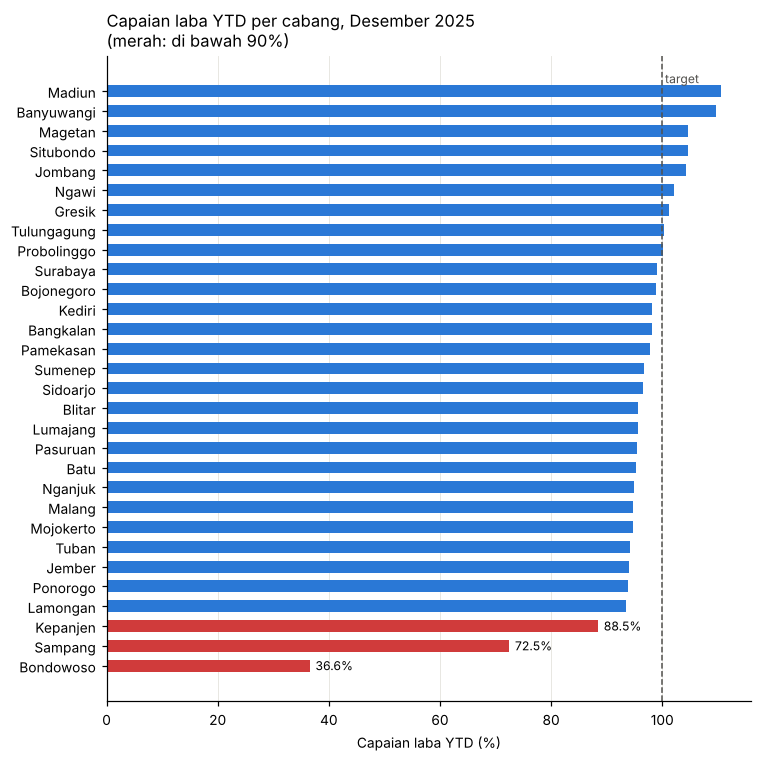

In [9]:
urut = cabang.sort_values("capaian_laba_ytd")
warna = [MERAH if x < 90 else BIRU for x in urut["capaian_laba_ytd"]]

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(urut["nama_cabang"], urut["capaian_laba_ytd"], color=warna, height=0.6)
ax.axvline(100, color="#52514e", lw=1, ls="--")
ax.text(100.5, 29.4, "target", color="#52514e", fontsize=8)

for i, (nama, nilai) in enumerate(zip(urut["nama_cabang"], urut["capaian_laba_ytd"])):
    if nilai < 90:
        ax.text(nilai + 1, i, f"{nilai:.1f}%", va="center", fontsize=8)

ax.set_xlabel("Capaian laba YTD (%)")
ax.set_title("Capaian laba YTD per cabang, Desember 2025\n(merah: di bawah 90%)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(GAMBAR + "capaian_laba_cabang.png")
plt.show()

Capaian tertinggi ada di Madiun dan Banyuwangi, keduanya juga punya pertumbuhan
kredit paling tinggi (sekitar 15-16% setahun).

Tiga cabang berada di bawah 90%: Bondowoso, Sampang, dan Kepanjen. Bondowoso
paling jauh tertinggal, labanya baru sepertiga dari target.

## 4. Kredit Bermasalah (NPL)

In [10]:
query('''
    SELECT nama_cabang, wilayah,
           COUNT(*) AS jumlah_bulan_npl_di_atas_5,
           MIN(periode) AS pertama_kali,
           MAX(npl) AS npl_tertinggi
    FROM v_kinerja_cabang
    WHERE npl > 5
    GROUP BY nama_cabang, wilayah
''')

,nama_cabang,wilayah,jumlah_bulan_npl_di_atas_5,pertama_kali,npl_tertinggi
0,Bondowoso,Tapal Kuda,12,2025-01,7.36
1,Sampang,Madura & Pantura,24,2024-01,6.98


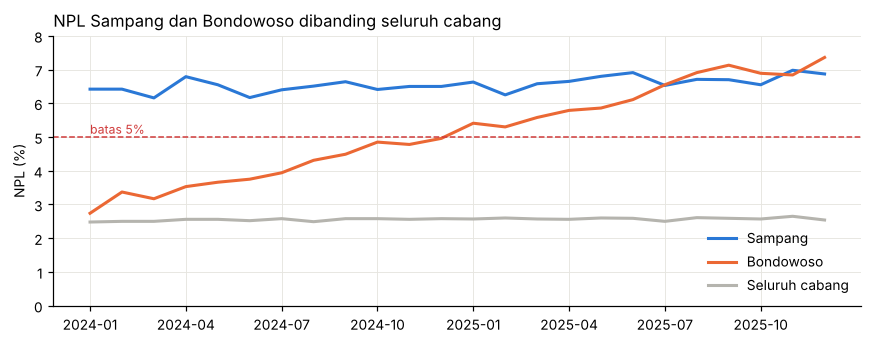

In [11]:
npl = query('''
    SELECT periode, nama_cabang, npl
    FROM v_kinerja_cabang
    WHERE nama_cabang IN ('Bondowoso', 'Sampang')
''').pivot(index="periode", columns="nama_cabang", values="npl")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(npl.index, npl["Sampang"], color=BIRU, lw=2, label="Sampang")
ax.plot(npl.index, npl["Bondowoso"], color=ORANYE, lw=2, label="Bondowoso")
ax.plot(total["periode"], total["npl"], color=ABU, lw=2, label="Seluruh cabang")
ax.axhline(5, color=MERAH, lw=1, ls="--")
ax.text(0, 5.1, "batas 5%", color=MERAH, fontsize=8)

ax.set_xticks(range(0, 24, 3))
ax.set_ylabel("NPL (%)")
ax.set_ylim(0, 8)
ax.set_title("NPL Sampang dan Bondowoso dibanding seluruh cabang", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(GAMBAR + "tren_npl.png")
plt.show()

Dua cabang dengan NPL di atas 5% punya pola yang berbeda:
- **Sampang** sudah di atas 5% sejak awal 2024 dan bertahan selama 24 bulan.
  Masalahnya sudah lama, bukan kejadian baru.
- **Bondowoso** awalnya sekitar 3%, lalu naik terus dan melewati 5% mulai Januari 2025.
  Kenaikannya belum berhenti sampai Desember 2025.

NPL seluruh cabang relatif stabil di kisaran 2,5%, jadi kenaikan di Bondowoso
bukan pengaruh kondisi umum.

## 5. Penyebab Laba di Bawah Target

Untuk melihat penyebabnya, laba 2025 dibandingkan dengan laba 2024. Perubahan
laba dipecah menjadi empat komponen:

perubahan laba = perubahan pendapatan bunga - perubahan beban bunga + perubahan pendapatan non bunga - perubahan biaya operasional

Angka positif berarti komponen itu menambah laba, negatif berarti mengurangi.

In [12]:
penyebab = query('''
    WITH per_tahun AS (
        SELECT kode_cabang, nama_cabang, tahun,
               SUM(pendapatan_bunga) AS pb, SUM(beban_bunga) AS bb,
               SUM(pendapatan_nonbunga) AS nb, SUM(biaya_operasional) AS bo,
               SUM(laba_sebelum_pajak) AS laba, SUM(target_laba) AS target_laba
        FROM v_kinerja_cabang
        GROUP BY kode_cabang, nama_cabang, tahun
    )
    SELECT a.nama_cabang,
           ROUND(100.0 * a.laba / a.target_laba, 2) AS capaian_laba_2025,
           ROUND(a.laba - b.laba, 0)  AS perubahan_laba,
           ROUND(a.pb - b.pb, 0)      AS dari_pendapatan_bunga,
           ROUND(-(a.bb - b.bb), 0)   AS dari_beban_bunga,
           ROUND(a.nb - b.nb, 0)      AS dari_pendapatan_nonbunga,
           ROUND(-(a.bo - b.bo), 0)   AS dari_biaya_operasional
    FROM per_tahun a
    JOIN per_tahun b ON a.kode_cabang = b.kode_cabang AND b.tahun = 2024
    WHERE a.tahun = 2025
    ORDER BY capaian_laba_2025
''')
penyebab.head(6)

,nama_cabang,capaian_laba_2025,perubahan_laba,dari_pendapatan_bunga,dari_beban_bunga,dari_pendapatan_nonbunga,dari_biaya_operasional
0,Bondowoso,36.60,-6337.0,396.0,486.0,128.0,-7347.0
1,Sampang,72.50,-537.0,942.0,635.0,-51.0,-2063.0
2,Kepanjen,88.48,857.0,4659.0,514.0,996.0,-5312.0
3,Lamongan,93.55,1949.0,5277.0,590.0,682.0,-4599.0
4,Ponorogo,93.81,2002.0,3891.0,-362.0,346.0,-1874.0
5,Jember,94.03,4855.0,10274.0,850.0,1419.0,-7688.0


In [13]:
# Biaya operasional dibandingkan dengan pendapatan, 2024 dan 2025
query('''
    SELECT nama_cabang, tahun,
           ROUND(SUM(biaya_operasional), 0) AS biaya_operasional,
           ROUND(SUM(kredit_bermasalah) / 12, 0) AS rata2_kredit_bermasalah,
           ROUND(100.0 * SUM(beban_bunga + biaya_operasional)
                 / SUM(pendapatan_bunga + pendapatan_nonbunga), 2) AS bopo
    FROM v_kinerja_cabang
    WHERE nama_cabang IN ('Bondowoso', 'Sampang', 'Kepanjen')
    GROUP BY nama_cabang, tahun
    ORDER BY nama_cabang, tahun
''')

,nama_cabang,tahun,biaya_operasional,rata2_kredit_bermasalah,bopo
0,Bondowoso,2024,37975.0,24182.0,81.14
1,Bondowoso,2025,45322.0,39735.0,89.86
2,Kepanjen,2024,81565.0,42019.0,76.00
3,Kepanjen,2025,86877.0,46048.0,76.31
4,Sampang,2024,36265.0,30730.0,88.23
5,Sampang,2025,38328.0,33089.0,89.30


Pada ketiga cabang, pendapatan bunga tetap naik. Yang membuat laba tertinggal
adalah biaya operasional yang naik lebih cepat.

- **Bondowoso**: laba 2025 turun dibanding 2024. Kenaikan biaya operasional jauh
  lebih besar dari tambahan pendapatan. Rata-rata kredit bermasalahnya juga naik,
  jadi kemungkinan besar sebagian kenaikan biaya berasal dari pencadangan kredit
  macet. Pertumbuhan kreditnya juga rendah, hanya sekitar 3,6%.
- **Sampang**: polanya mirip Bondowoso tapi lebih ringan. Labanya sedikit turun
  dan BOPO-nya tertinggi kedua.
- **Kepanjen**: labanya masih naik, tapi tidak cukup untuk mengejar target. Kenaikan
  biaya operasionalnya lebih besar dari kenaikan pendapatan bunga.

Data ini tidak memisahkan biaya pencadangan dari biaya operasional lain, jadi
dugaan soal pencadangan masih perlu dicek dengan data yang lebih rinci.

## 6. Capaian Kredit

In [14]:
cabang.sort_values("capaian_kredit")[["nama_cabang", "wilayah", "capaian_kredit", "capaian_dpk",
                                      "growth_kredit_yoy", "npl"]].head(5)

,nama_cabang,wilayah,capaian_kredit,capaian_dpk,growth_kredit_yoy,npl
29,Bondowoso,Tapal Kuda,92.01,103.15,3.57,7.36
17,Lumajang,Malang Raya,93.01,93.20,2.37,1.61
28,Sampang,Madura & Pantura,93.81,99.34,3.21,6.87
27,Kepanjen,Malang Raya,95.69,102.53,5.27,3.85
22,Mojokerto,Surabaya Raya,96.89,97.80,6.61,2.82


Selain Bondowoso dan Sampang yang sudah dibahas, Lumajang punya capaian kredit
terendah ketiga dan capaian DPK paling rendah, dengan pertumbuhan kredit hanya
sekitar 2% setahun. Kualitas kreditnya bagus (NPL sekitar 1,6%) dan capaian
labanya masih di atas 95%, jadi masalah Lumajang lebih ke penyaluran kredit yang
lambat, bukan risiko.

Kalau dibiarkan, laba Lumajang akan ikut tertinggal tahun depan karena target
dihitung dari pertumbuhan kredit.

## 7. Efisiensi

In [15]:
efisiensi = query('''
    SELECT nama_cabang, wilayah,
           ROUND(100.0 * SUM(beban_bunga + biaya_operasional)
                 / SUM(pendapatan_bunga + pendapatan_nonbunga), 2) AS bopo_2025,
           ROUND(100.0 * SUM(laba_sebelum_pajak) / AVG(kredit_outstanding), 2) AS laba_per_kredit_2025
    FROM v_kinerja_cabang
    WHERE tahun = 2025
    GROUP BY nama_cabang, wilayah
    ORDER BY bopo_2025 DESC
''')
print("Median BOPO:", efisiensi["bopo_2025"].median())
efisiensi.head(6)

Median BOPO: 70.13499999999999


,nama_cabang,wilayah,bopo_2025,laba_per_kredit_2025
0,Bondowoso,Tapal Kuda,89.86,1.19
1,Sampang,Madura & Pantura,89.30,1.30
2,Blitar,Mataraman,78.66,2.72
3,Kepanjen,Malang Raya,76.31,3.11
4,Ngawi,Mataraman,75.30,3.23
5,Gresik,Surabaya Raya,74.78,3.08


Setelah Bondowoso dan Sampang, ada dua cabang lain yang BOPO-nya jauh di atas median (70%):
- **Blitar** (78,7%): NPL-nya 4,1%, sudah mendekati batas 5%. Perlu dipantau supaya
  tidak mengikuti pola Bondowoso.
- **Ngawi** (75,3%): NPL-nya termasuk paling rendah (1,4%), jadi biaya yang tinggi
  bukan berasal dari kredit macet. Labanya masih sesuai target, tapi efisiensinya
  bisa dibandingkan dengan cabang sekitar seperti Magetan dan Ponorogo yang BOPO-nya
  sekitar 64-67%.

## Temuan Utama

1. Kredit seluruh cabang tumbuh sekitar 10% dan DPK sekitar 8% sepanjang 2025,
   tapi capaian laba turun dari 100% di 2024 menjadi 97% di 2025.
2. Bondowoso perlu perhatian paling cepat: NPL naik dari 5,0% ke 7,4% dalam setahun,
   capaian laba YTD hanya 36,6%, dan pertumbuhan kreditnya rendah.
3. Sampang memiliki NPL di atas 5% selama 24 bulan berturut-turut. Masalahnya
   sudah lama sehingga perlu penanganan kredit bermasalah, bukan sekadar pemantauan.
4. Kepanjen berada di bawah target laba (88,5%) karena biaya operasional naik
   lebih cepat dari pendapatan.
5. Lumajang tertinggal di penyaluran kredit dan penghimpunan dana (capaian kredit 93%,
   DPK 93%, pertumbuhan kredit sekitar 2%), walaupun kualitas kreditnya baik.
6. Blitar perlu dipantau karena NPL-nya 4,1% dan BOPO-nya tinggi.
7. Madiun dan Banyuwangi menjadi cabang dengan capaian tertinggi, didorong
   pertumbuhan kredit sekitar 15-16%.

Catatan: seluruh data adalah simulasi, sehingga temuan ini hanya menggambarkan
cara analisisnya, bukan kondisi bank yang sebenarnya.

In [16]:
conn.close()